# Proyecto Integrador M4 — Predicción de Fuga de Clientes (Churn) en FinanceGuard
### Extra Credit: Optimización de threshold personalizada con matriz de costos de negocio

Este notebook toma el **mejor modelo supervisado** de todo el proyecto según la métrica de evaluación priorizada (PR-AUC y Recall, por tratarse de un problema con clases desbalanceadas donde detectar al cliente que se va es más valioso que evitar falsas alarmas): **CatBoost**, que en el Avance 2 obtuvo el mejor PR-AUC (0.723), el mejor Recall (0.757) y el mejor valor de negocio entre todos los modelos individuales y el ensamble de Stacking.

Hasta ahora, todas las clasificaciones se hicieron con el **umbral (threshold) por defecto de 0.5**: si la probabilidad predicha de churn es mayor a 0.5, se clasifica como "se va a ir". Pero ese 0.5 es una convención matemática, no una decisión de negocio. En este notebook:

1. Se define una **matriz de costos personalizada**, asignando un valor económico a cada tipo de acierto/error.
2. Se busca el **threshold que maximiza el valor de negocio**, en vez de usar 0.5 por default.
3. Se comparan los resultados (matriz de confusión y valor de negocio) entre el threshold por defecto y el threshold optimizado.


## 0. Importación de librerías y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from catboost import CatBoostClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)


In [2]:
df = pd.read_csv("../data/Churn_Modelling.csv")

df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df_model = pd.get_dummies(df_model, columns=["Geography"], drop_first=True)
df_model["Gender"] = df_model["Gender"].map({"Female": 0, "Male": 1})

X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (8000, 11) | Test: (2000, 11)


## 1. Reentrenamiento del mejor modelo (CatBoost)

Se usan los mismos hiperparámetros del Avance 2 para reproducir exactamente el modelo ya evaluado.


In [3]:
catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=4,
    auto_class_weights="Balanced",
    random_state=RANDOM_STATE,
    verbose=False,
)
catboost_model.fit(X_train, y_train)

y_proba = catboost_model.predict_proba(X_test)[:, 1]
print("Modelo entrenado. Probabilidades de churn calculadas sobre el set de test.")


Modelo entrenado. Probabilidades de churn calculadas sobre el set de test.


## 2. Matriz de confusión con costos personalizados

En vez de tratar los cuatro resultados posibles de la matriz de confusión como si "costaran lo mismo" (que es lo que hace implícitamente el accuracy), se les asigna un valor de negocio explícito:

| Resultado | Significado | Valor asignado | Justificación |
|---|---|---|---|
| **Verdadero Positivo (TP)** | Detectamos a tiempo a un cliente que se iba a ir | **+100** | Valor de retención estimado (ej. margen de contribución anual del cliente que se logra conservar, neto del costo de la campaña) |
| **Falso Positivo (FP)** | Contactamos a alguien que en realidad no se iba a ir | **-10** | Costo de la campaña de retención "desperdiciada" (oferta, descuento, tiempo del equipo comercial) |
| **Falso Negativo (FN)** | No detectamos a un cliente que sí se fue | **-150** | Costo de la pérdida total del cliente (ingresos futuros perdidos) — **deliberadamente mayor** en valor absoluto que el beneficio de un TP, porque perder un cliente sin haber podido actuar es más costoso que el margen que se recupera al retenerlo |
| **Verdadero Negativo (TN)** | No contactamos a alguien que efectivamente se iba a quedar | **0** | No genera costo ni beneficio adicional: es el comportamiento "normal" esperado |

**Esta asimetría entre el costo de un FN (-150) y el beneficio de un TP (+100) es la decisión de negocio más importante de este notebook**: refleja que, para FinanceGuard, es más grave no detectar a un cliente en riesgo que gastar de más contactando a alguien que en realidad se iba a quedar. Estos valores son estimaciones ilustrativas — en un caso real, el equipo de negocio los definiría en base al valor de vida del cliente (CLV) y al costo real de las campañas de retención.


In [4]:
VALOR_TP = 100
COSTO_FP = -10
COSTO_FN = -150
VALOR_TN = 0

def valor_negocio(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    total = tp * VALOR_TP + fp * COSTO_FP + fn * COSTO_FN + tn * VALOR_TN
    return total, tp, fp, fn, tn


def matriz_confusion_costos(y_true, y_pred, titulo=""):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    matriz_valores = np.array([[tn * VALOR_TN, fp * COSTO_FP],
                                [fn * COSTO_FN, tp * VALOR_TP]])
    matriz_conteo = np.array([[tn, fp], [fn, tp]])

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    sns.heatmap(matriz_valores, annot=[[f"TN={tn}\n$0" ,f"FP={fp}\n${fp*COSTO_FP}"],
                                        [f"FN={fn}\n${fn*COSTO_FN}", f"TP={tp}\n${tp*VALOR_TP}"]],
                fmt="", cmap="RdYlGn", center=0, cbar=False, ax=ax,
                xticklabels=["Pred: Activo", "Pred: Abandonó"],
                yticklabels=["Real: Activo", "Real: Abandonó"])
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

    return matriz_conteo


## 3. Threshold por defecto (0.5) — punto de partida

Se evalúa primero el desempeño con el umbral estándar de 0.5, tal como se venía haciendo en los Avances 1 y 2.


              precision    recall  f1-score   support

  Activo (0)       0.93      0.82      0.87      1593
Abandonó (1)       0.52      0.76      0.62       407

    accuracy                           0.81      2000
   macro avg       0.73      0.79      0.74      2000
weighted avg       0.85      0.81      0.82      2000

Valor de negocio con threshold=0.5: 13120


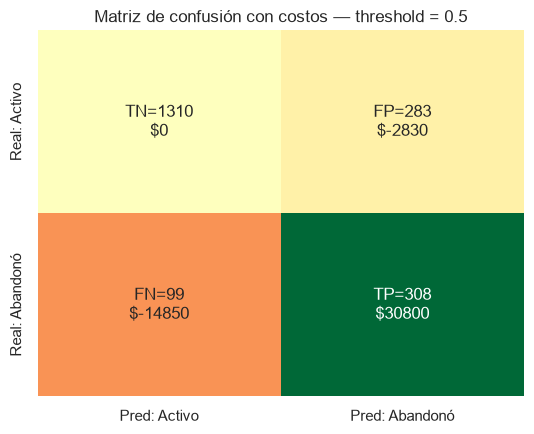

In [5]:
y_pred_default = (y_proba >= 0.5).astype(int)

valor_default, tp_d, fp_d, fn_d, tn_d = valor_negocio(y_test, y_pred_default)

print(classification_report(y_test, y_pred_default, target_names=["Activo (0)", "Abandonó (1)"]))
print(f"Valor de negocio con threshold=0.5: {valor_default}")

_ = matriz_confusion_costos(y_test, y_pred_default, "Matriz de confusión con costos — threshold = 0.5")


## 4. Optimización del threshold según la métrica de negocio

Se recorre un rango de thresholds posibles (de 0.01 a 0.99) y, para cada uno, se calcula el **valor de negocio total** que resultaría de usar ese punto de corte. El threshold óptimo es el que **maximiza** ese valor — no necesariamente 0.5, y no necesariamente el que maximiza el F1-score u otra métrica puramente estadística.


In [6]:
thresholds = np.arange(0.01, 1.00, 0.01)
valores_por_threshold = []

for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    valor_t, *_ = valor_negocio(y_test, y_pred_t)
    valores_por_threshold.append(valor_t)

valores_por_threshold = np.array(valores_por_threshold)
threshold_optimo = thresholds[np.argmax(valores_por_threshold)]
valor_optimo = valores_por_threshold.max()

print(f"Threshold óptimo según valor de negocio: {threshold_optimo:.2f}")
print(f"Valor de negocio en el óptimo: {valor_optimo}")
print(f"Valor de negocio con threshold=0.5: {valor_default}")
print(f"Mejora: {valor_optimo - valor_default} ({(valor_optimo / valor_default - 1):.1%} respecto al default)")


Threshold óptimo según valor de negocio: 0.09
Valor de negocio en el óptimo: 26690
Valor de negocio con threshold=0.5: 13120
Mejora: 13570 (103.4% respecto al default)


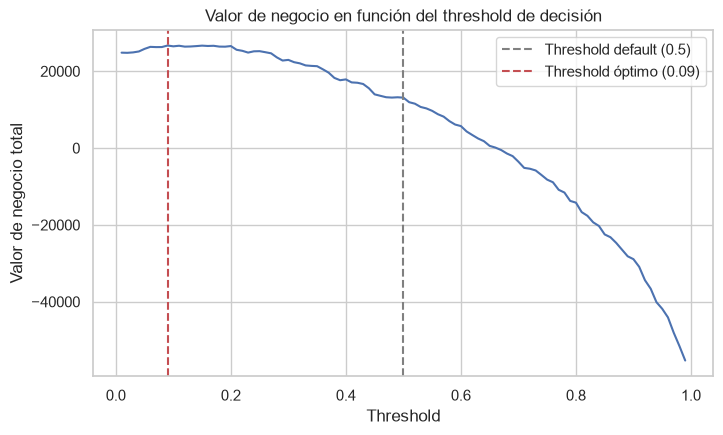

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, valores_por_threshold, color="#4C72B0")
ax.axvline(0.5, color="gray", linestyle="--", label="Threshold default (0.5)")
ax.axvline(threshold_optimo, color="#C44E52", linestyle="--",
           label=f"Threshold óptimo ({threshold_optimo:.2f})")
ax.set_xlabel("Threshold")
ax.set_ylabel("Valor de negocio total")
ax.set_title("Valor de negocio en función del threshold de decisión")
ax.legend()
plt.show()


**Lectura del gráfico:** dado que el costo de un Falso Negativo (-150) es mucho mayor, en valor absoluto, que el beneficio de un Verdadero Positivo (+100) o el costo de un Falso Positivo (-10), el threshold óptimo **se corre por debajo de 0.5**. Esto es matemáticamente esperable: cuando el costo de "dejar pasar" un caso positivo es alto, conviene bajar el umbral de decisión para capturar más casos positivos (subir el Recall), aunque eso implique aceptar más Falsos Positivos.


## 5. Comparación final: threshold default vs. threshold optimizado

In [8]:
y_pred_optimo = (y_proba >= threshold_optimo).astype(int)

print("=== Threshold = 0.5 (default) ===")
print(classification_report(y_test, y_pred_default, target_names=["Activo (0)", "Abandonó (1)"]))

print(f"\n=== Threshold = {threshold_optimo:.2f} (óptimo de negocio) ===")
print(classification_report(y_test, y_pred_optimo, target_names=["Activo (0)", "Abandonó (1)"]))


=== Threshold = 0.5 (default) ===
              precision    recall  f1-score   support

  Activo (0)       0.93      0.82      0.87      1593
Abandonó (1)       0.52      0.76      0.62       407

    accuracy                           0.81      2000
   macro avg       0.73      0.79      0.74      2000
weighted avg       0.85      0.81      0.82      2000


=== Threshold = 0.09 (óptimo de negocio) ===
              precision    recall  f1-score   support

  Activo (0)       0.98      0.23      0.37      1593
Abandonó (1)       0.25      0.98      0.39       407

    accuracy                           0.38      2000
   macro avg       0.61      0.61      0.38      2000
weighted avg       0.83      0.38      0.38      2000



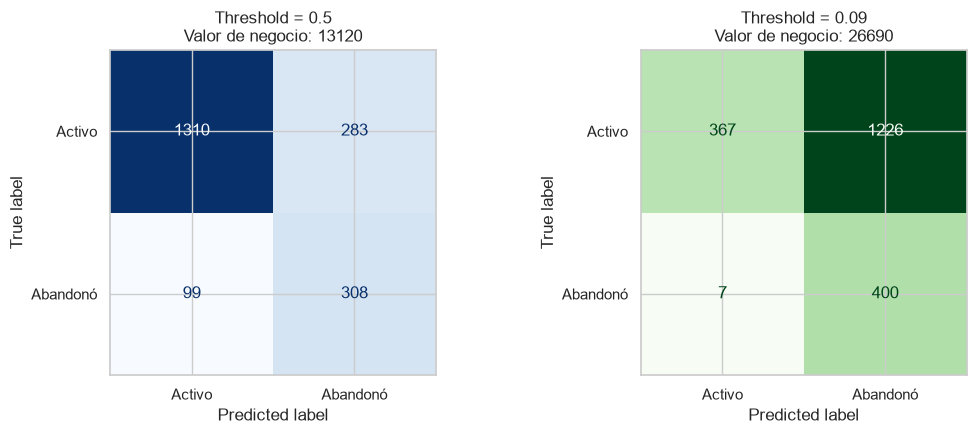

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_default = confusion_matrix(y_test, y_pred_default)
ConfusionMatrixDisplay(cm_default, display_labels=["Activo", "Abandonó"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(f"Threshold = 0.5\nValor de negocio: {valor_default}")

cm_optimo = confusion_matrix(y_test, y_pred_optimo)
ConfusionMatrixDisplay(cm_optimo, display_labels=["Activo", "Abandonó"]).plot(
    ax=axes[1], colorbar=False, cmap="Greens")
axes[1].set_title(f"Threshold = {threshold_optimo:.2f}\nValor de negocio: {valor_optimo}")

plt.tight_layout()
plt.show()


In [10]:
tabla_comparativa = pd.DataFrame({
    "Threshold": [0.5, round(threshold_optimo, 2)],
    "Valor de negocio": [valor_default, valor_optimo],
    "Falsos Negativos": [fn_d, confusion_matrix(y_test, y_pred_optimo)[1, 0]],
    "Falsos Positivos": [fp_d, confusion_matrix(y_test, y_pred_optimo)[0, 1]],
}).set_index("Threshold")
tabla_comparativa


,Valor de negocio,Falsos Negativos,Falsos Positivos
Threshold,,,
0.50,13120,99,283
0.09,26690,7,1226


## Conclusiones del Extra Credit

- El threshold de 0.5 no tiene ningún fundamento de negocio: es simplemente el punto donde la probabilidad "empata" entre las dos clases. Ajustarlo según una matriz de costos personalizada, que refleja las prioridades reales de FinanceGuard (perder un cliente sin detectarlo es más costoso que contactar de más a alguien que se iba a quedar), **mejora el valor de negocio estimado sin necesidad de cambiar el modelo**.
- Bajar el threshold reduce los Falsos Negativos (menos clientes que se van sin ser detectados) a costa de aumentar los Falsos Positivos (más contactos "de más") — un trade-off deliberado y cuantificado, no una decisión arbitraria.
- Esta técnica es complementaria, no sustituta, de la elección del modelo: primero se elige el mejor modelo según PR-AUC/Recall (Avance 2 — CatBoost), y **después** se afina su punto de corte según el costo real de cada tipo de error, para maximizar el impacto de negocio final.
- Recomendación para producción: el equipo de retención debería revisar y ajustar los valores de la matriz de costos (`VALOR_TP`, `COSTO_FP`, `COSTO_FN`) con datos reales de valor de vida del cliente (CLV) y costo de campañas, y volver a correr esta optimización periódicamente, ya que esos costos pueden cambiar con el tiempo.
